In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
df = pd.read_csv('Data/measurement.csv')

In [4]:
df.head()

,borehole_id,profile_id,depth,temperature
0,1,1,20.000,-14.500
1,1,1,50.000,-13.800
2,2,1,11.305,-2.958
3,2,1,18.632,-3.355
4,2,1,29.399,-3.618


In [17]:
bores = df[(df['temperature']==0) & (df['depth'] == 0)]['borehole_id'].unique()

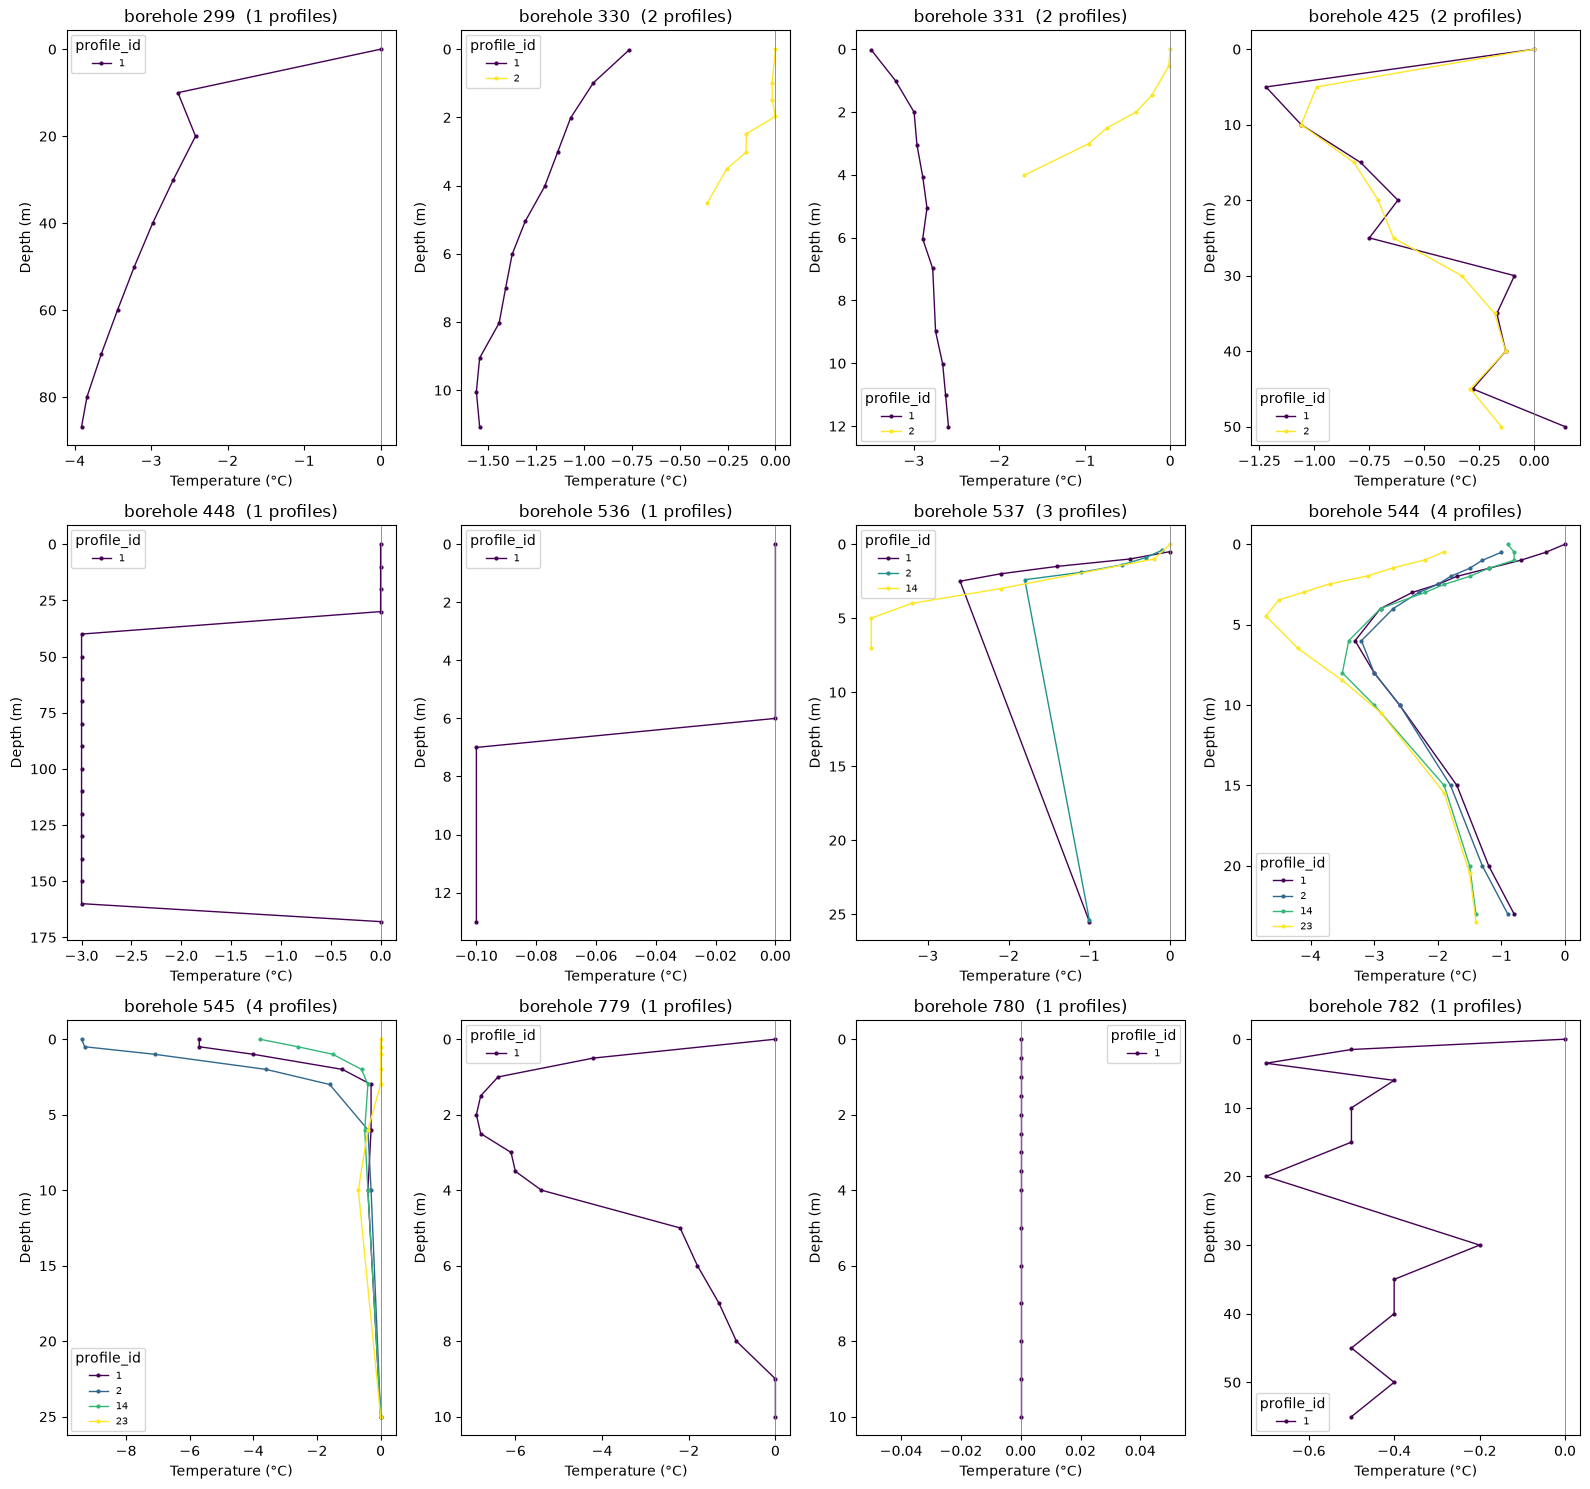

In [20]:
only_surface_zero = True

zero_profiles = set(
    df.loc[(df['depth'] == 0) & (df['temperature'] == 0), 'profile_id']
)

def plot_borehole(ax, b):
    sub = df[df['borehole_id'] == b].dropna(subset=['depth', 'temperature'])
    if only_surface_zero:
        sub = sub[sub['profile_id'].isin(zero_profiles)]

    pids = sorted(sub['profile_id'].unique())
    colors = plt.cm.viridis(np.linspace(0, 1, max(len(pids), 2)))

    for c, pid in zip(colors, pids):
        g = sub[sub['profile_id'] == pid].sort_values('depth')
        ax.plot(g['temperature'], g['depth'], '-o', ms=2, lw=1, color=c,
                label=str(pid) if len(pids) <= 6 else None)

    ax.axvline(0, color='gray', lw=0.6) 
    ax.invert_yaxis() 
    ax.set_title(f'borehole {b}  ({len(pids)} profiles)')
    ax.set_xlabel('Temperature (°C)')
    ax.set_ylabel('Depth (m)')
    if 0 < len(pids) <= 6:
        ax.legend(title='profile_id', fontsize=7)

ncols = 4
nrows = int(np.ceil(len(bores) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 5 * nrows))
for ax, b in zip(axes.flat, bores):
    plot_borehole(ax, b)
for ax in axes.flat[len(bores):]:
    ax.set_visible(False) 
plt.tight_layout()

In [22]:
profile = pd.read_csv('Data/profile.csv')
source = pd.read_csv('Data/source.csv')

In [38]:
profile[(profile['borehole_id']==544) & (profile['id'] == 1)].head()

,borehole_id,id,source_id,measurement_origin,date_min,date_max,time,utc_offset,equilibrium,notes
958,544,1,vilesov1962b,published,1957-08-21,1957-08-31,NaN,NaN,true,NaN


In [35]:
source[source['id']=='vilesov1962b']

,id,author,year,type,title,url,language,container_title,volume,issue,page,version,editor,collection_title,collection_number,publisher
308,vilesov1962b,Е. Н. Вилесов [E. N. Vilesov],1962,book,Температура льда: Стационарные наблюдения [Ice...,NaN,ru,NaN,3.0,NaN,NaN,NaN,NaN,Материалы Гляциологических Исследований: Тянь-...,NaN,Акаде́мия нау́к СССР > Институт Географии [Aca...
